# Notebook 56 — Variational autoencoders and the ELBO

The deterministic autoencoder reconstructed inputs but did not define a reliable distribution over latent codes. A variational autoencoder (VAE) makes the latent representation probabilistic and encourages it to remain compatible with a known prior.

## Learning goals

- distinguish a fixed latent code from an approximate posterior distribution;
- interpret encoder means and log-variances;
- implement the reparameterization trick;
- implement the Gaussian KL-divergence term;
- connect reconstruction loss, KL divergence, and the ELBO;
- reconstruct inputs and generate new images from the prior;
- observe the trade-off between reconstruction and latent regularization.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("device:", DEVICE)

device: mps


## 1. Dataset

We use the same noisy binary shapes as in the [previous notebook](./55_autoencoders_and_latent_spaces.ipynb). Keeping the data fixed lets us compare deterministic reconstruction with probabilistic latent modeling.

In [2]:
SHAPE_NAMES = ("horizontal", "vertical", "cross", "border")


def make_binary_shape_images(number_images, image_size=8, noise_probability=0.02, seed=0):
    generator = torch.Generator().manual_seed(seed)
    images = torch.zeros(number_images, image_size, image_size)
    labels = torch.randint(0, 4, (number_images,), generator=generator)

    for index, label in enumerate(labels.tolist()):
        row = int(torch.randint(1, image_size - 1, (), generator=generator))
        column = int(torch.randint(1, image_size - 1, (), generator=generator))
        if label == 0:
            images[index, row, :] = 1.0
        elif label == 1:
            images[index, :, column] = 1.0
        elif label == 2:
            images[index, row, :] = 1.0
            images[index, :, column] = 1.0
        else:
            top = int(torch.randint(0, image_size - 3, (), generator=generator))
            left = int(torch.randint(0, image_size - 3, (), generator=generator))
            bottom = int(torch.randint(top + 2, image_size, (), generator=generator))
            right = int(torch.randint(left + 2, image_size, (), generator=generator))
            images[index, top, left : right + 1] = 1.0
            images[index, bottom, left : right + 1] = 1.0
            images[index, top : bottom + 1, left] = 1.0
            images[index, top : bottom + 1, right] = 1.0

    noise = torch.rand(number_images, image_size, image_size, generator=generator)
    images = torch.where(noise < noise_probability, 1.0 - images, images)
    return images, labels


train_images, train_labels = make_binary_shape_images(4000, seed=SEED)
evaluation_images, evaluation_labels = make_binary_shape_images(1000, seed=SEED + 1)
assert train_images.shape == (4000, 8, 8)

## 2. From one code to a distribution

A deterministic encoder returns one vector z for each image. A VAE encoder instead defines an approximate posterior distribution. Here, **posterior** means a distribution over the latent code after observing a particular image. Because the true posterior is generally difficult to calculate, the encoder learns an approximation to it. See [VAE ELBO and reparameterization](../notes/13-generative-models/vae-elbo-and-reparameterization.md#prior-posterior-and-approximate-posterior) for a concise comparison of the prior, true posterior, and approximate posterior.

$$
q_\phi(z\mid x)=\mathcal{N}(\mu(x),\mathrm{diag}(\sigma^2(x))).
$$

For every latent dimension, the encoder predicts a mean and a log-variance. The mean describes the center of the distribution; the variance describes its uncertainty or spread.

We predict log-variance rather than variance directly because a neural-network output can be any real number, while exponentiation guarantees a positive variance:

$$
\sigma^2=\exp(\mathrm{logvar}),\qquad
\sigma=\exp(0.5\,\mathrm{logvar}).
$$

For latent width $D$, both mean and log-variance have shape $(N,D)$. For one image $n$, row `mean[n]` contains the $D$ coordinates of the distribution center, while row `log_variance[n]` contains the spread of those same $D$ coordinates. The two rows therefore work together to describe one distribution for that image; they are not two separate latent codes. Sampling once from each of the $N$ distributions produces the actual latent-code tensor $z$, also with shape $(N,D)$.


The Gaussian is called **diagonal** because its covariance matrix contains the $D$ variances on the diagonal and assumes zero covariance between different latent dimensions. The encoder therefore predicts only $D$ variance values per image rather than a full $D\times D$ covariance matrix.

## 3. Reparameterization trick

We need a latent sample for reconstruction, but the encoder does not output that sample directly. It outputs the parameters $\mu$ and $\sigma$ of a Gaussian distribution. We then need to draw $z$ from that image-specific distribution. A direct sampling operation can be treated as an opaque random step, making it unclear how a reconstruction change should update the predicted distribution parameters.

The reparameterization trick separates the random part from the learned part:

$$
\epsilon\sim\mathcal{N}(0,I),\qquad
z=\mu+\sigma\odot\epsilon.
$$

Here $\epsilon$ (epsilon) is ordinary random noise sampled from a **standard normal distribution**: it has mean zero and variance one. It is not predicted by the encoder and is not a learned parameter. It normally has the same shape $(N,D)$ as the mean and log-variance, giving every image and latent dimension an independent noise value. Fresh epsilon values can produce different latent samples for the same input image.

Multiplying epsilon by $\sigma$ changes its spread from one to the encoder's predicted standard deviation. Adding $\mu$ moves its center from zero to the predicted mean. The resulting $z$ is therefore centered at $\mu$ and has variance $\sigma^2$ in each independent latent dimension.

For a one-dimensional example, if $\mu=2$, $\sigma=0.5$, and the random draw is $\epsilon=-1.2$, then $z=2+0.5(-1.2)=1.4$. Another epsilon draw would produce another valid sample centered around two.

The crucial point is that the randomness now lives only in $\epsilon$, which does not depend on the encoder parameters. After epsilon is drawn, the path from $\mu$ and $\sigma$ to $z$ consists only of multiplication and addition. In particular, $z$ changes directly with $\mu$, and its change with $\sigma$ is scaled by epsilon. Autograd can therefore propagate reconstruction gradients through $z$ into both encoder outputs.

The complete shape flow is:

~~~text
image x -> encoder -> mean (N, D), log_variance (N, D)
                                      |
epsilon (N, D) ~ standard normal      |
             \________________________/
                         |
         z = mean + std * epsilon -> decoder -> reconstruction
~~~

### Exercise 1 — Implement reparameterization

In [5]:
def reparameterize(mean, log_variance, epsilon=None):
    if mean.shape != log_variance.shape:
        raise ValueError("mean and log_variance must have equal shapes")
    # calculate standard deviation from log-variance.
    standard_deviation = torch.exp(0.5 * log_variance)
    if epsilon is None:
        # sample standard-normal noise with matching shape, device, and dtype.
        epsilon = torch.randn_like(mean)
    # transform epsilon into a sample from the encoder distribution.
    return mean + standard_deviation * epsilon


toy_mean = torch.tensor([[1.0, -1.0], [0.5, 2.0]], requires_grad=True)
toy_log_variance = torch.zeros_like(toy_mean, requires_grad=True)
toy_epsilon = torch.tensor([[0.25, -0.5], [1.0, 0.0]])
toy_z = reparameterize(toy_mean, toy_log_variance, toy_epsilon)
torch.testing.assert_close(toy_z, toy_mean + toy_epsilon)
toy_z.sum().backward()
assert toy_mean.grad is not None
assert toy_log_variance.grad is not None

### Why multiply log-variance by 0.5?

The encoder predicts log-variance, so `log_variance` represents $\ln(\sigma^2)$. Reparameterization needs the standard deviation $\sigma$, not the variance $\sigma^2$. Taking the square root of variance is equivalent to halving its logarithm before exponentiating:

$$
\sigma=\sqrt{\sigma^2}=\exp\left(\frac{1}{2}\ln(\sigma^2)\right).
$$

Therefore `torch.exp(0.5 * log_variance)` converts predicted log-variance into a positive standard deviation. For example, log-variance zero gives standard deviation one; log-variance $\ln 4$ gives standard deviation two.

## 4. KL divergence from the prior

A **prior** is a latent distribution chosen before observing a particular image. The usual VAE choice is the standard normal prior

$$
p(z)=\mathcal{N}(0,I).
$$

The zero vector means the prior is centered at zero. The identity covariance matrix $I$ means every latent dimension has variance one and the different dimensions have zero covariance under the prior. Variance one is called **unit variance**; its standard deviation is also one because $\sqrt{1}=1$.

The prior has two roles. During training, KL divergence encourages each image-specific encoder distribution $q(z\mid x)$ to remain reasonably close to this shared region. During generation, there is no input image and therefore no encoder distribution; we sample $z$ directly from $p(z)$ and pass it to the decoder. Prior regularization makes these sampled locations more likely to be regions the decoder encountered during training.

Let $\ell_j=\log(\sigma_j^2)$ be the predicted log-variance in latent dimension $j$. For a diagonal Gaussian, the KL divergence from the standard normal prior is

$$
D_{KL}(q\|p)=\frac{1}{2}\sum_j
\left(\mu_j^2+\exp(\ell_j)-\ell_j-1\right).
$$

If $\mu_j=0$ and $\ell_j=0$, then $\sigma_j^2=\exp(0)=1$. The encoder distribution in that dimension is therefore exactly the same as the prior. Substitution into its KL contribution gives

$$
0^2+\exp(0)-0-1=0.
$$

If this holds in every dimension, all contributions sum to zero. KL divergence is nonnegative and grows as the encoder distribution moves away from the prior through a shifted mean or a different variance.

Zero KL is the minimum for prior matching, but forcing every image to have exactly the same $\mathcal{N}(0,I)$ posterior would make the latent sample contain no image-specific information. VAE training balances reconstruction pressure, which asks the latent variables to describe the input, against KL pressure, which keeps their distributions compatible with the prior.

### Exercise 2 — Implement Gaussian KL divergence

In [8]:
def gaussian_kl_divergence(mean, log_variance):
    if mean.shape != log_variance.shape:
        raise ValueError("mean and log_variance must have equal shapes")
    # calculate KL for every latent dimension and sum over D.
    # Return one KL value for each batch example, with shape (N,).
    return 0.5 * torch.sum(
        torch.exp(log_variance) + mean**2 - 1.0 - log_variance, dim=1
    )


zero_mean = torch.zeros(3, 2)
zero_log_variance = torch.zeros(3, 2)
torch.testing.assert_close(
    gaussian_kl_divergence(zero_mean, zero_log_variance),
    torch.zeros(3),
)
shifted_kl = gaussian_kl_divergence(torch.ones(3, 2), zero_log_variance)
torch.testing.assert_close(shifted_kl, torch.ones(3))

## 5. Tiny variational autoencoder

The encoder shares a hidden representation and uses two output layers: one for mean and one for log-variance. The decoder still receives one sampled z and returns one Bernoulli logit per pixel.

During training, forward returns everything needed by the loss: reconstruction logits, mean, log-variance, and the sampled latent code. During deterministic reconstruction we can decode the mean instead of sampling.

### Exercise 3 — Complete the VAE

In [11]:
class TinyVAE(nn.Module):
    def __init__(self, image_size=8, hidden_dim=32, latent_dim=2):
        super().__init__()
        self.image_size = image_size
        self.input_dim = image_size * image_size
        self.latent_dim = latent_dim
        self.encoder_hidden = nn.Linear(self.input_dim, hidden_dim)
        self.mean_output = nn.Linear(hidden_dim, latent_dim)
        self.log_variance_output = nn.Linear(hidden_dim, latent_dim)
        self.decoder_hidden = nn.Linear(latent_dim, hidden_dim)
        self.decoder_output = nn.Linear(hidden_dim, self.input_dim)

    def encode(self, images):
        flattened = images.reshape(images.shape[0], -1)
        hidden = F.relu(self.encoder_hidden(flattened))
        # return mean and log-variance from their separate heads.
        mean = self.mean_output(hidden)
        log_variance = self.log_variance_output(hidden)
        return mean, log_variance

    def decode(self, latent_codes):
        # map latent codes through the decoder and restore image shape.
        hidden = F.relu(self.decoder_hidden(latent_codes))
        reconstruction_logits = self.decoder_output(hidden)
        return reconstruction_logits.reshape(-1, self.image_size, self.image_size)

    def forward(self, images):
        # encode, sample with reparameterization, and decode.
        # Return reconstruction_logits, mean, log_variance, latent_codes.
        encoded_mean, encoded_log_variance = self.encode(images)
        latent_codes = reparameterize(encoded_mean, encoded_log_variance)
        reconstruction_logits = self.decode(latent_codes)
        return reconstruction_logits, encoded_mean, encoded_log_variance, latent_codes


torch.manual_seed(SEED)
shape_model = TinyVAE()
toy_outputs = shape_model(train_images[:5])
toy_logits, toy_mean, toy_log_variance, toy_codes = toy_outputs
assert toy_logits.shape == (5, 8, 8)
assert toy_mean.shape == toy_log_variance.shape == toy_codes.shape == (5, 2)

## 6. ELBO and the VAE loss

The VAE ideally maximizes the marginal likelihood $p_\theta(x)$, which combines every possible latent explanation of an observed image. With a neural decoder, evaluating that continuous integral exactly is generally impractical. The encoder distribution $q_\phi(z\mid x)$ lets us optimize a tractable lower bound instead.

For the full intuition behind probability versus likelihood, marginalizing an unobserved variable, the meaning of **exact**, and why likelihood is useful, see [Probability, likelihood, and tractability](../notes/13-generative-models/probability-likelihood-and-tractability.md). For the formal bound derivation and its connection to the true posterior, see [VAE ELBO and reparameterization](../notes/13-generative-models/vae-elbo-and-reparameterization.md).

The evidence lower bound used for training is

$$
ELBO(x)=
\mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]
-D_{KL}(q_\phi(z\mid x)\|p(z)).
$$

The expectation rewards latent samples that let the decoder reconstruct the input. The KL term keeps the encoder distribution compatible with the prior. We do not evaluate exact marginal likelihood in this notebook; we minimize the negative ELBO instead.

In code, we sum pixel reconstruction NLL within each image, sum KL across latent dimensions, and then average both quantities across the batch. This keeps both terms on a per-example scale.

A beta value is included for controlled experiments. Beta equal to one corresponds to the standard VAE objective; changing it intentionally changes the balance between reconstruction and prior matching.

### Exercise 4 — Implement the VAE loss

In [12]:
def vae_loss(reconstruction_logits, targets, mean, log_variance, beta=1.0):
    if reconstruction_logits.shape != targets.shape:
        raise ValueError("reconstruction_logits and targets must match")
    # calculate summed pixel BCE for each image, then average over N.
    reconstruction_loss = F.binary_cross_entropy_with_logits(
        reconstruction_logits, targets, reduction="sum"
    ) / reconstruction_logits.shape[0]
    # calculate mean KL across the batch.
    kl_loss = gaussian_kl_divergence(mean, log_variance).mean()
    total_loss = reconstruction_loss + beta * kl_loss
    return total_loss, reconstruction_loss, kl_loss


toy_total, toy_reconstruction, toy_kl = vae_loss(
    toy_logits, train_images[:5], toy_mean, toy_log_variance
)
torch.testing.assert_close(toy_total, toy_reconstruction + toy_kl)
assert toy_reconstruction.ndim == toy_kl.ndim == toy_total.ndim == 0
assert toy_reconstruction > 0 and toy_kl >= 0

## 7. Train the VAE

Unlike deterministic autoencoder training, the loss changes slightly across passes because the latent sample contains fresh epsilon noise. The optimizer nevertheless follows a valid stochastic gradient estimate of the negative ELBO.

### Exercise 5 — Complete the training loop

epoch  1: total=43.243, reconstruction=43.176, KL=0.067
epoch  5: total=32.325, reconstruction=31.750, KL=0.575
epoch 10: total=28.771, reconstruction=27.361, KL=1.410
epoch 15: total=26.911, reconstruction=24.830, KL=2.081
epoch 20: total=26.237, reconstruction=23.972, KL=2.265
epoch 25: total=25.745, reconstruction=23.311, KL=2.434
epoch 30: total=25.330, reconstruction=22.798, KL=2.532


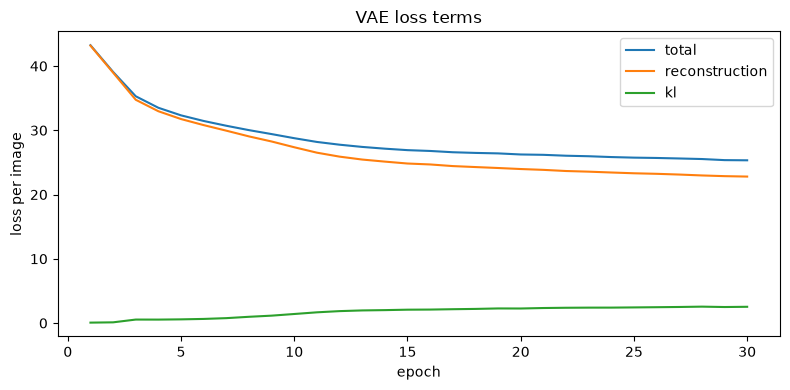

In [14]:
def train_vae(model, images, epochs=30, batch_size=128, learning_rate=1e-3, beta=1.0):
    loader = DataLoader(TensorDataset(images), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {"total": [], "reconstruction": [], "kl": []}

    for epoch in range(epochs):
        totals = {"total": 0.0, "reconstruction": 0.0, "kl": 0.0}
        number_images = 0
        model.train()
        for (batch,) in loader:
            batch = batch.to(next(model.parameters()).device)
            # clear gradients, run the model, and calculate all loss terms.
            optimizer.zero_grad()
            reconstruction_logits, mean, log_variance, latent_codes = model(batch)
            total_loss, reconstruction_loss, kl_loss = vae_loss(
                reconstruction_logits, batch, mean, log_variance, beta=beta
            )
            
            # backpropagate total_loss and update parameters.
            total_loss.backward()
            optimizer.step()
            batch_count = batch.shape[0]
            totals["total"] += total_loss.item() * batch_count
            totals["reconstruction"] += reconstruction_loss.item() * batch_count
            totals["kl"] += kl_loss.item() * batch_count
            number_images += batch_count

        for name in history:
            history[name].append(totals[name] / number_images)
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(
                f"epoch {epoch + 1:2d}: total={history['total'][-1]:.3f}, "
                f"reconstruction={history['reconstruction'][-1]:.3f}, "
                f"KL={history['kl'][-1]:.3f}"
            )

    return history


torch.manual_seed(SEED)
model = TinyVAE().to(DEVICE)
training_history = train_vae(model, train_images)

fig, axis = plt.subplots(figsize=(8, 4))
for name, values in training_history.items():
    axis.plot(np.arange(1, len(values) + 1), values, label=name)
axis.set(title="VAE loss terms", xlabel="epoch", ylabel="loss per image")
axis.legend()
plt.tight_layout()
plt.show()
assert training_history["total"][-1] < training_history["total"][0]

## 8. Deterministic and stochastic reconstruction

For a stable reconstruction, decode the posterior mean. For a stochastic reconstruction, sample z from the posterior first. Both use information from the input image, so neither is unconditional generation.

### Exercise 6 — Compare reconstruction modes

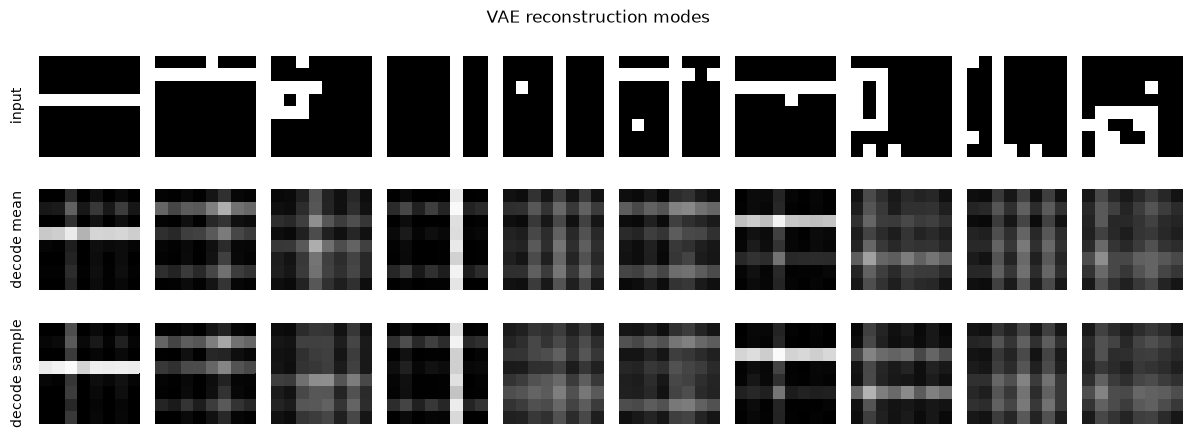

In [16]:
@torch.no_grad()
def reconstruct_with_vae(model, images, sample=False):
    model.eval()
    images = images.to(next(model.parameters()).device)
    mean, log_variance = model.encode(images)
    # choose the mean or a reparameterized sample, then decode and sigmoid.
    latent_codes = mean if not sample else reparameterize(mean, log_variance)
    reconstruction_logits = model.decode(latent_codes)
    reconstruction_probs = torch.sigmoid(reconstruction_logits)
    return reconstruction_probs


examples = evaluation_images[:10]
mean_reconstructions = reconstruct_with_vae(model, examples, sample=False).cpu()
sampled_reconstructions = reconstruct_with_vae(model, examples, sample=True).cpu()

fig, axes = plt.subplots(3, 10, figsize=(12, 4.5))
rows = (examples, mean_reconstructions, sampled_reconstructions)
labels = ("input", "decode mean", "decode sample")
for row, (images, label) in enumerate(zip(rows, labels)):
    for column, image in enumerate(images):
        axes[row, column].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[row, column].axis("off")
    axes[row, 0].text(
        -0.15, 0.5, label, transform=axes[row, 0].transAxes,
        rotation=90, va="center", ha="right",
    )
plt.suptitle("VAE reconstruction modes")
plt.tight_layout()
plt.show()

## 9. Generation from the prior

This is the key generative step. We do not start from an image and do not call the encoder. Instead, we sample latent codes from the standard normal prior and pass them directly to the decoder:

~~~text
z sampled from N(0, I) -> decoder -> new image probabilities
~~~

### Exercise 7 — Sample new images

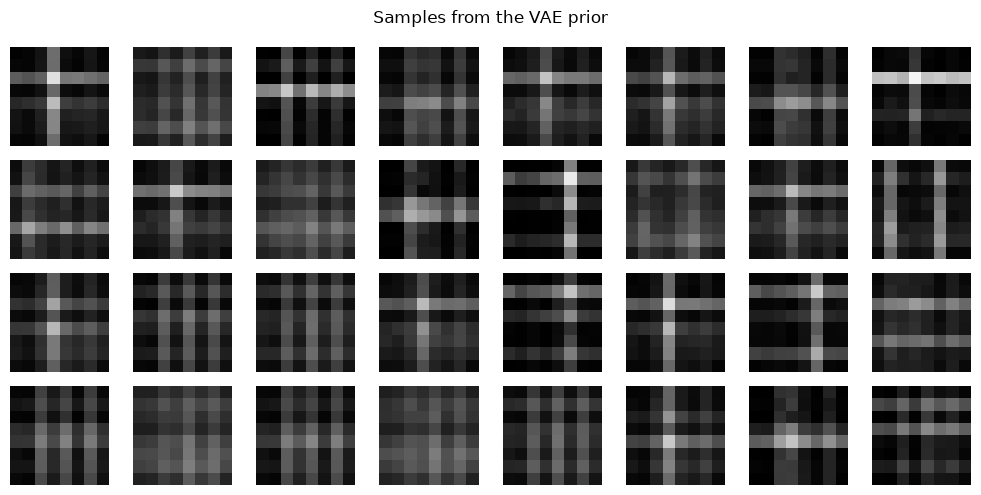

In [18]:
@torch.no_grad()
def sample_from_vae(model, number_images, seed=0):
    model.eval()
    device = next(model.parameters()).device
    generator = torch.Generator(device=device).manual_seed(seed)
    # sample (number_images, latent_dim) standard-normal codes.
    latent_codes = torch.randn(number_images, model.latent_dim, generator=generator, device=device)
    # decode, apply sigmoid, and return images on the CPU.
    reconstruction_logits = model.decode(latent_codes)
    reconstruction_probs = torch.sigmoid(reconstruction_logits)
    return reconstruction_probs.cpu()


generated_images = sample_from_vae(model, 32, seed=SEED + 10)
assert generated_images.shape == (32, 8, 8)
assert torch.all((generated_images >= 0) & (generated_images <= 1))

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for axis, image in zip(axes.flat, generated_images):
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.axis("off")
plt.suptitle("Samples from the VAE prior")
plt.tight_layout()
plt.show()

## 10. Inspect posterior means

The KL term encourages individual approximate posteriors toward the standard normal prior, but it does not force class clusters to separate. We can inspect the posterior means and compare their occupied region with standard-normal reference samples.

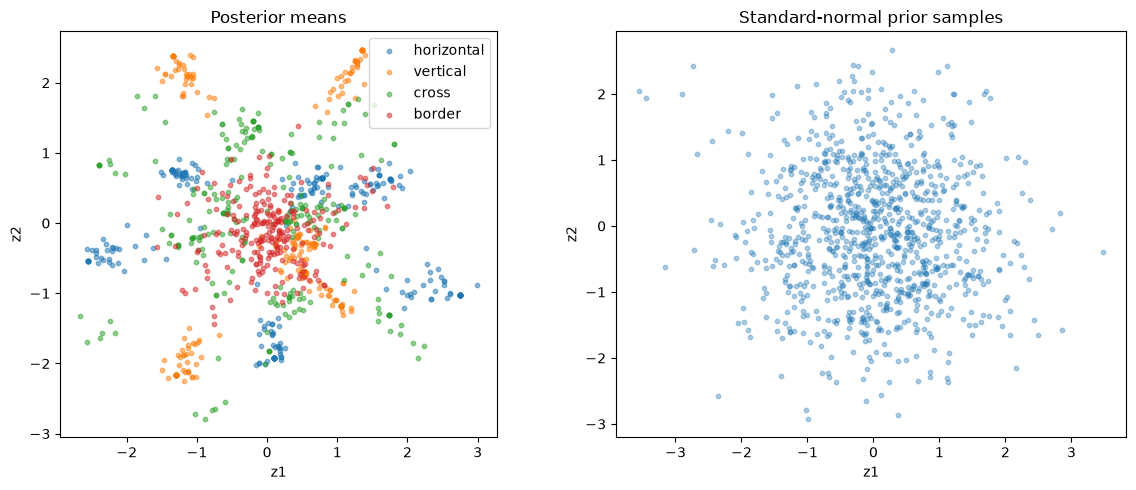

In [19]:
@torch.no_grad()
def encode_vae_means(model, images):
    model.eval()
    mean, _ = model.encode(images.to(next(model.parameters()).device))
    return mean.cpu()


posterior_means = encode_vae_means(model, evaluation_images)
reference_generator = torch.Generator().manual_seed(SEED + 20)
prior_reference = torch.randn(1000, 2, generator=reference_generator)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for label, name in enumerate(SHAPE_NAMES):
    selected = evaluation_labels == label
    axes[0].scatter(
        posterior_means[selected, 0], posterior_means[selected, 1],
        s=10, alpha=0.5, label=name,
    )
axes[0].set(title="Posterior means", xlabel="z1", ylabel="z2")
axes[0].legend()
axes[1].scatter(prior_reference[:, 0], prior_reference[:, 1], s=10, alpha=0.35)
axes[1].set(title="Standard-normal prior samples", xlabel="z1", ylabel="z2")
for axis in axes:
    axis.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

## 11. What the ELBO guarantees—and what it does not

The ELBO is a lower bound on the model log-likelihood:

$$
\log p_\theta(x)\geq\mathrm{ELBO}(x).
$$

Maximizing the ELBO improves a tractable objective related to likelihood, but the bound can be loose. The reconstruction term is estimated using latent samples, and the KL term regularizes the approximate posterior. Unlike the autoregressive model, this notebook does not directly calculate exact image likelihood.

The two loss terms compete. Very weak KL regularization can recreate the irregular latent-space problem of a deterministic autoencoder. Very strong KL pressure can make the encoder distributions nearly independent of the input, causing the decoder to ignore z; this is called posterior collapse.

## Reflection

1. Why does the VAE encoder return mean and log-variance instead of one code?
2. Why predict log-variance rather than variance directly?
3. How does reparameterization preserve gradient flow?
4. When is the Gaussian KL term zero?
5. What do the reconstruction and KL terms each encourage?
6. Why is decoding a posterior mean still reconstruction rather than generation?
7. Why can a VAE sample from the prior more meaningfully than a deterministic autoencoder?
8. Why is the ELBO not the same as exact log-likelihood?
9. What is posterior collapse?

### Answers

1. 
2. 
3. 
4. 
5. 
6. 
7. 
8. 
9. 